# Semana 7: Tu primera red profunda con Keras 3: Fashion-MNIST

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT

## Qué se resuelve

El notebook del curso (`YourFirstDeepNN_FashionMNIST_Keras3.ipynb`) no trae espacios `# TODO`: es una demostración completa que termina con una lista de **experimentos sugeridos**. Esas son las actividades que se resuelven en la sección 7: comparar regresión logística contra la red FC, identificar las clases que más se confunden, y probar una segunda capa oculta, `tanh`/`sigmoid`, `Dropout`, otros `batch_size` y `lr_rate`, y más épocas. La comparación con una CNN queda fuera: es el tema de la siguiente clase.

## Cómo se ejecutó (declarado, no escondido)

- Keras 3 con backend **TensorFlow** en CPU de un Mac M4, entorno `si3003-keras`.
- El notebook original se conserva tal cual (sección 0 a 6, ejecutado con `MODEL_TYPE = "logistic"`); lo añadido va en la sección 7 y dos líneas que guardan resultados (`hist_logistic`, `res_logistic`).
- Todos los números salen de la ejecución real; TensorFlow en CPU no garantiza bit a bit el mismo resultado entre máquinas.

# Lecture 07 – Introducción a Deep Learning
### Universidad EAFIT | 2026 - Introducción a la IA

---

## ¿Qué es Deep Learning?

Las **redes neuronales** son modelos de Machine Learning que aprenden representaciones a partir de datos ajustando parámetros distribuidos en capas interconectadas.

### Deep Learning vs. Machine Learning Tradicional

En el **Machine Learning tradicional**, un experto humano suele diseñar manualmente las features relevantes:

```text
Raw Input → Feature Engineering (humano) → Features → Modelo ML → Output
```

En **Deep Learning**, la red puede aprender automáticamente representaciones útiles a partir de los datos:

```text
Raw Input → DNN (aprende representaciones jerárquicas) → Output
```

> **La clave**: al apilar capas con transformaciones **no lineales**, la red puede aprender representaciones progresivamente más útiles para la tarea.

---

## ¿Qué construiremos en este notebook?

Implementaremos y compararemos **dos modelos con Keras 3** para clasificar imágenes del dataset **Fashion-MNIST**:

| Modelo | Descripción | Frontera de decisión |
|---|---|---|
| **Regresión Logística** | Una sola capa lineal | Lineal |
| **Red Neuronal FC** | Capa oculta + activación ReLU | No lineal |

Fashion-MNIST es más desafiante que MNIST: algunas categorías, como **Shirt**, **T-shirt/top**, **Pullover** y **Coat**, tienen apariencias similares.

Al final podremos observar cómo añadir una capa oculta con una activación no lineal aumenta la capacidad del modelo.

---


## 0. Configuración del entorno

Usaremos **Keras 3**, una API de Deep Learning que permite definir, entrenar y evaluar redes neuronales con una interfaz de alto nivel.

Keras 3 es **multi-backend**: puede trabajar sobre backends compatibles como TensorFlow, JAX o PyTorch. En este notebook utilizaremos exclusivamente la API pública de `keras`.

> A diferencia de PyTorch, en este ejemplo no moveremos manualmente el modelo con `.to(device)`. El backend seleccionado por Keras gestiona la ejecución sobre CPU/GPU según el entorno.


In [1]:
import keras
from keras import layers
import matplotlib.pyplot as plt
import numpy as np

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
## 1. Carga del Dataset: Fashion-MNIST

**Fashion-MNIST** contiene imágenes de prendas de vestir y calzado:

- **60,000 imágenes** para entrenamiento
- **10,000 imágenes** para prueba
- Cada imagen tiene **28×28 píxeles** en escala de grises
- **10 clases**

| Etiqueta | Clase |
|---:|---|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

### Representación de una imagen como vector de features

Las imágenes originales contienen intensidades entre 0 y 255. Las normalizamos al rango **[0, 1]**:

$$x_{\text{norm}} = \frac{x}{255}$$

Nuestros modelos fully-connected recibirán cada imagen como un vector de:

$$28\times 28 = 784$$

features.

No es necesario hacer el `reshape` manualmente antes del entrenamiento: añadiremos una capa `Flatten()` dentro del modelo.


In [2]:
# Keras incluye Fashion-MNIST directamente.
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Normalización: uint8 [0,255] -> float32 [0,1]
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

print(f"Muestras de entrenamiento : {len(X_train)}")
print(f"Muestras de prueba        : {len(X_test)}")
print(f"Tamaño de una imagen      : {X_train[0].shape} -> (alto, ancho)")
print(f"Tipo X_train              : {X_train.dtype}")
print(f"Tipo y_train              : {y_train.dtype}")
print(f"Número de clases          : {len(class_names)}")
print(f"Clases                    : {class_names}")


Muestras de entrenamiento : 60000
Muestras de prueba        : 10000
Tamaño de una imagen      : (28, 28) -> (alto, ancho)
Tipo X_train              : float32
Tipo y_train              : uint8
Número de clases          : 10
Clases                    : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### ¿Dónde está el `DataLoader`?

Con Keras podemos entregar directamente arrays de NumPy a `model.fit()`:

```python
model.fit(
    X_train,
    y_train,
    batch_size=64,
    shuffle=True,
)
```

Keras divide los datos internamente en **mini-batches**.

Para este notebook:

| Concepto | PyTorch | Keras 3 |
|---|---|---|
| Dataset | `torchvision.datasets.FashionMNIST` | `keras.datasets.fashion_mnist.load_data()` |
| Mini-batches | `DataLoader(..., batch_size=64)` | `model.fit(..., batch_size=64)` |
| Mezclar ejemplos | `shuffle=True` en `DataLoader` | `shuffle=True` en `fit()` |
| Aplanar imagen | `images.view(-1, 784)` | `layers.Flatten()` |

### ¿Por qué usar mini-batches?

Con un batch de tamaño $B$, el modelo calcula gradientes usando $B$ ejemplos antes de actualizar sus parámetros.

- **Full-batch**: una actualización por epoch.
- **SGD puro**: una actualización por ejemplo.
- **Mini-batch**: compromiso práctico entre eficiencia computacional y ruido del gradiente.

En Fashion-MNIST usaremos:

```python
batch_size = 64
```


In [3]:
batch_size = 64

n_train_batches = int(np.ceil(len(X_train) / batch_size))
n_test_batches  = int(np.ceil(len(X_test) / batch_size))

print(f"Batches de entrenamiento : {n_train_batches}")
print(f"Batches de prueba        : {n_test_batches}")

# Simulamos el primer batch únicamente para explorar sus dimensiones.
images = X_train[:batch_size]
labels = y_train[:batch_size]

print(f"\nShape del batch de imágenes  : {images.shape}")
print(f"Shape del batch de etiquetas : {labels.shape}")
print(f"Etiquetas (primeras 10)      : {labels[:10].tolist()}")
print("Clases (primeras 10)        :", [class_names[label] for label in labels[:10]])


Batches de entrenamiento : 938
Batches de prueba        : 157

Shape del batch de imágenes  : (64, 28, 28)
Shape del batch de etiquetas : (64,)
Etiquetas (primeras 10)      : [9, 0, 0, 3, 0, 2, 7, 2, 5, 5]
Clases (primeras 10)        : ['Ankle boot', 'T-shirt/top', 'T-shirt/top', 'Dress', 'T-shirt/top', 'Pullover', 'Sneaker', 'Pullover', 'Sandal', 'Sandal']


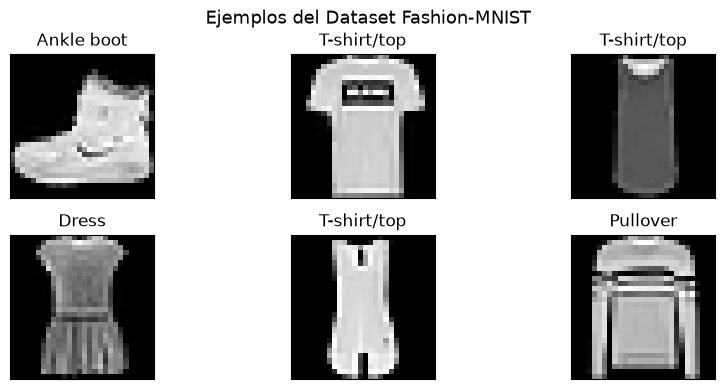

In [4]:
# Visualizamos 6 imágenes de ejemplo.
fig = plt.figure(figsize=(9, 4))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.tight_layout()
    plt.imshow(images[i], cmap="gray", interpolation="none")
    plt.title(class_names[labels[i]])
    plt.xticks([])
    plt.yticks([])

plt.suptitle("Ejemplos del Dataset Fashion-MNIST", fontsize=13, y=1.02)
plt.show()


---
## 2. Definición de modelos

### Revisión: del perceptrón a las redes neuronales

Para clasificación multiclase podemos transformar los **logits** $z_k$ en probabilidades usando Softmax:

$$
P(y_k\mid\mathbf{x})
=
\frac{e^{z_k}}
{\sum_{j=1}^{K}e^{z_j}}
$$

La predicción será:

$$
\hat y = \arg\max_k z_k
$$

Aplicar `argmax` sobre logits o sobre probabilidades Softmax produce la misma clase.

### Modelo 1: Regresión logística

Arquitectura:

```text
Input(28×28) → Flatten(784) → Dense(10) → logits
```

Es un modelo **lineal** respecto a las 784 features de píxel.

### Modelo 2: Red neuronal fully-connected

Arquitectura:

```text
Input(28×28) → Flatten(784) → Dense(128) → ReLU → Dense(10) → logits
```

La activación ReLU:

$$
g(x)=\max(0,x)
$$

introduce **no linealidad**. Sin una activación no lineal entre capas, varias capas `Dense` consecutivas seguirían representando una única transformación lineal.

En Fashion-MNIST esta mayor capacidad es especialmente útil porque varias categorías de ropa son visualmente parecidas.


In [5]:
input_shape = (28, 28)
output_dim  = 10

# =============================================================================
# MODELO 1: Regresión Logística
# Input(28,28) -> Flatten(784) -> Dense(10)
# =============================================================================
logistic_model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        layers.Flatten(name="flatten"),
        layers.Dense(output_dim, name="logits"),
    ],
    name="LogisticRegression",
)

# =============================================================================
# MODELO 2: Red Fully-Connected
# Input(28,28) -> Flatten(784) -> Dense(128) -> ReLU -> Dense(10)
# =============================================================================
fc_model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="hidden"),
        layers.Dense(output_dim, name="logits"),
    ],
    name="FCNeuralNetwork",
)

print("Modelos definidos exitosamente.\n")
print("LogisticRegression : 784 -> Dense(10)")
print("FCNeuralNetwork    : 784 -> Dense(128) -> ReLU -> Dense(10)")


Modelos definidos exitosamente.

LogisticRegression : 784 -> Dense(10)
FCNeuralNetwork    : 784 -> Dense(128) -> ReLU -> Dense(10)


In [6]:
print("=== Regresión Logística ===")
logistic_model.summary()

print("\n=== Red Neuronal FC ===")
fc_model.summary()

print(f"\nParámetros LogisticRegression : {logistic_model.count_params():,}")
print(f"Parámetros FCNeuralNetwork    : {fc_model.count_params():,}")


=== Regresión Logística ===


Model: "LogisticRegression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden (Dense)                  │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)


Parámetros LogisticRegression : 7,850
Parámetros FCNeuralNetwork    : 101,770


---
## 3. Configuración del entrenamiento

### Hiperparámetros

- **`epochs = 10`**: número de pasadas completas por los datos.
- **`batch_size = 64`**: ejemplos usados por actualización.
- **`lr_rate = 0.001`**: learning rate de Adam.

### Función de pérdida: Sparse Categorical Cross-Entropy

Las etiquetas de Fashion-MNIST están almacenadas como enteros entre 0 y 9. Cada entero identifica una categoría de prenda.

Por eso usaremos:

```python
keras.losses.SparseCategoricalCrossentropy(from_logits=True)
```

`from_logits=True` es importante porque la última capa produce **logits**, no probabilidades.

Conceptualmente, la pérdida incorpora la transformación Softmax necesaria para calcular la cross-entropy de forma numéricamente estable. Por eso **no añadimos `Softmax` a la última capa**.

### Optimizador: Adam

Usaremos:

```python
keras.optimizers.Adam(learning_rate=0.001)
```

Keras conectará el optimizador, la función de pérdida y las métricas mediante `model.compile()`.


In [7]:
epochs  = 10
lr_rate = 0.001

loss_fn = keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

def compile_model(model):
    # Creamos un optimizador nuevo para cada modelo.
    optimizer = keras.optimizers.Adam(learning_rate=lr_rate)

    model.compile(
        optimizer=optimizer,
        loss=loss_fn,
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ],
    )

print(f"Épocas de entrenamiento : {epochs}")
print(f"Batch size              : {batch_size}")
print(f"Learning rate           : {lr_rate}")
print("Loss                    : SparseCategoricalCrossentropy(from_logits=True)")
print("Optimizer               : Adam")


Épocas de entrenamiento : 10
Batch size              : 64
Learning rate           : 0.001
Loss                    : SparseCategoricalCrossentropy(from_logits=True)
Optimizer               : Adam


### Elegimos el modelo

Cambia únicamente esta variable para repetir el experimento:

```python
MODEL_TYPE = "logistic"
```

o:

```python
MODEL_TYPE = "fc"
```


In [8]:
MODEL_TYPE = "logistic"   # "logistic" o "fc"

if MODEL_TYPE == "logistic":
    model = logistic_model
elif MODEL_TYPE == "fc":
    model = fc_model
else:
    raise ValueError("MODEL_TYPE debe ser 'logistic' o 'fc'")

compile_model(model)

print(f"Modelo seleccionado: {model.name}")
print(f"Parámetros entrenables: {model.count_params():,}")


Modelo seleccionado: LogisticRegression
Parámetros entrenables: 7,850


---
## 4. Ciclo de entrenamiento

En una implementación de bajo nivel, cada mini-batch requiere conceptualmente:

```text
1. Forward pass
2. Calcular loss
3. Calcular gradientes con backpropagation
4. Actualizar parámetros con el optimizador
```

Con Keras 3, `model.fit()` ejecuta este ciclo automáticamente:

```python
history = model.fit(...)
```

La correspondencia conceptual es:

| Concepto | Implementación manual | Keras 3 |
|---|---|---|
| Forward | `outputs = model(x)` | interno en `fit()` |
| Loss | `loss_fn(y, outputs)` | definido en `compile()` |
| Backpropagation | autodiferenciación | interno en `fit()` |
| Actualización | `optimizer.step/apply...` | interno en `fit()` |
| Mini-batches | loop explícito | `batch_size=64` |
| Epochs | loop externo | `epochs=10` |

### Backpropagation

Backpropagation usa la regla de la cadena para calcular:

$$
\frac{\partial\mathcal L}{\partial W^{(k)}}
=
\frac{\partial\mathcal L}{\partial z^{(k)}}
\frac{\partial z^{(k)}}{\partial W^{(k)}}
$$

Keras delega el cálculo automático de esos gradientes al backend seleccionado.


In [9]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=epochs,
    batch_size=batch_size,
    shuffle=True,
    verbose=1,
)

hist_logistic = history


Epoch 1/10


  1/938 ━━━━━━━━━━━━━━━━━━━━ 5:43 367ms/step - accuracy: 0.0781 - loss: 2.6123

 60/938 ━━━━━━━━━━━━━━━━━━━━ 0s 856us/step - accuracy: 0.5422 - loss: 1.4011  

136/938 ━━━━━━━━━━━━━━━━━━━━ 0s 745us/step - accuracy: 0.6449 - loss: 1.0870

213/938 ━━━━━━━━━━━━━━━━━━━━ 0s 713us/step - accuracy: 0.6871 - loss: 0.9508

...

869/938 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8627 - loss: 0.3967

898/938 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8625 - loss: 0.3970

917/938 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8626 - loss: 0.3971

938/938 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8625 - loss: 0.3972

938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8625 - loss: 0.3972 - val_accuracy: 0.8442 - val_loss: 0.4480


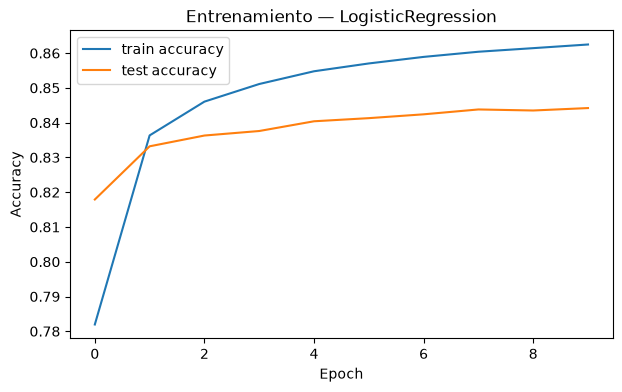

In [10]:
# Graficamos la evolución del entrenamiento.
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(f"Entrenamiento: {model.name}")
plt.legend()
plt.show()


### Logits vs. probabilidades

La última capa:

```python
layers.Dense(10)
```

no tiene activación. Por lo tanto produce **logits**.

Para interpretar esos valores como probabilidades usamos Softmax:

$$
P(y_k\mid x)
=
\frac{e^{z_k}}
{\sum_j e^{z_j}}
$$

Durante el entrenamiento no necesitamos añadir Softmax al modelo porque la loss fue configurada con `from_logits=True`.


In [11]:
# Tomamos una imagen de prueba.
sample = X_test[:1]
true_label = y_test[0]

# Forward pass directo: devuelve logits.
logits = model(sample, training=False)[0]

print("Logits:")
print(keras.ops.convert_to_numpy(logits))
print(
    f"\nSuma de logits: "
    f"{float(keras.ops.convert_to_numpy(keras.ops.sum(logits))):.4f} "
    "← NO tiene que ser 1"
)

# Convertimos logits a probabilidades.
probs = keras.ops.softmax(logits)
probs_np = keras.ops.convert_to_numpy(probs)

pred_class = int(np.argmax(probs_np))

print("\nProbabilidades (Softmax):")
for k, p in enumerate(probs_np):
    marker = " <- PREDICCIÓN" if k == pred_class else ""
    print(f"  {k}: {class_names[k]:12s} -> {p:.4f}{marker}")

print(f"\nSuma de probabilidades: {probs_np.sum():.6f}")
print(f"Clase real             : {true_label} -> {class_names[true_label]}")
print(f"Clase predicha         : {pred_class} -> {class_names[pred_class]}")


Logits:
[-7.5302544 -9.304546  -3.8491287 -4.74338   -4.510125   4.929885
 -3.2306385  4.383608   1.6873925  6.347452 ]

Suma de logits: -15.8197 ← NO tiene que ser 1

Probabilidades (Softmax):
  0: T-shirt/top  -> 0.0000
  1: Trouser      -> 0.0000
  2: Pullover     -> 0.0000
  3: Dress        -> 0.0000
  4: Coat         -> 0.0000
  5: Sandal       -> 0.1740
  6: Shirt        -> 0.0000
  7: Sneaker      -> 0.1008
  8: Bag          -> 0.0068
  9: Ankle boot   -> 0.7183 <- PREDICCIÓN

Suma de probabilidades: 1.000000
Clase real             : 9 -> Ankle boot
Clase predicha         : 9 -> Ankle boot


---
## 5. Evaluación del modelo

Una vez entrenado, evaluamos sobre las **10,000 imágenes de prueba**, que no se usan para actualizar los parámetros.

Con Keras:

```python
model.evaluate(X_test, y_test)
```

Durante `evaluate()` el modelo trabaja en modo inferencia automáticamente.

### Overfitting y generalización

Si el desempeño en entrenamiento aumenta mientras que el desempeño en prueba deja de mejorar o empeora, existe evidencia de **overfitting**.

Fashion-MNIST es más difícil que MNIST porque algunas categorías comparten patrones visuales similares, especialmente `T-shirt/top`, `Shirt`, `Pullover` y `Coat`.

Algunas estrategias comunes para mitigarlo son:

- Early Stopping
- Dropout
- Regularización L2
- Data augmentation
- Reducir la complejidad del modelo


In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=batch_size,
    verbose=0,
)

print(f"Loss en prueba     : {test_loss:.4f}")
print(f"Accuracy en prueba : {test_accuracy:.4f}")
print(
    f"→ {test_accuracy * 100:.2f}% de las "
    f"{len(X_test)} imágenes clasificadas correctamente"
)

res_logistic = (test_loss, test_accuracy)


Loss en prueba     : 0.4480
Accuracy en prueba : 0.8442
→ 84.42% de las 10000 imágenes clasificadas correctamente


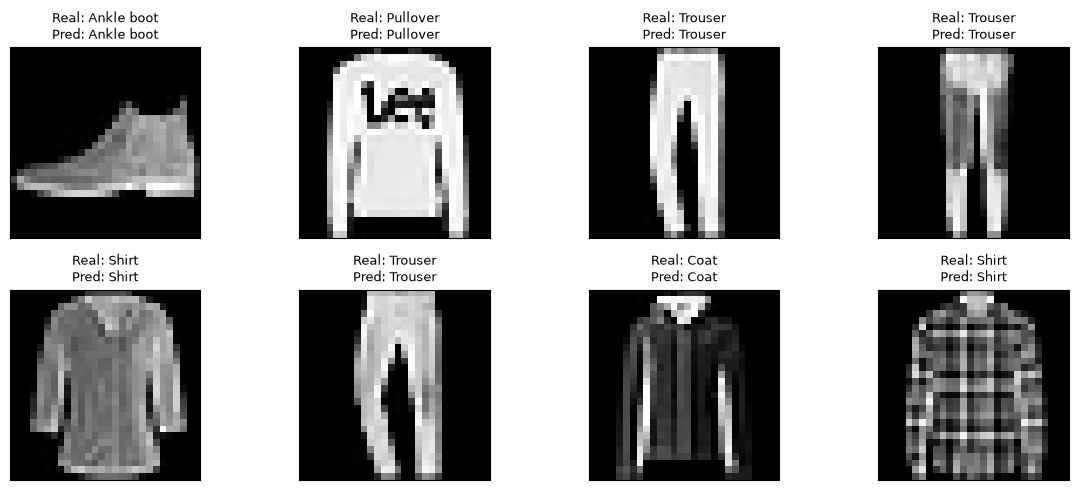

In [13]:
# Visualizamos algunas predicciones.
n = 8
logits_batch = model(X_test[:n], training=False)
predictions = keras.ops.convert_to_numpy(
    keras.ops.argmax(logits_batch, axis=1)
)

fig = plt.figure(figsize=(12, 5))

for i in range(n):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    plt.title(
        f"Real: {class_names[y_test[i]]}\n"
        f"Pred: {class_names[predictions[i]]}",
        fontsize=9,
    )
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
## 7. Actividades del notebook resueltas

El notebook termina con una lista de **experimentos sugeridos**. Aquí se resuelven con ejecuciones reales. Las celdas anteriores quedaron ejecutadas con `MODEL_TYPE = "logistic"`, que es el valor con el que viene el archivo; el modelo `fc` se entrena a continuación sin tocar nada de lo anterior.

Protocolo común a todos los experimentos: mismos datos normalizados, 10 épocas, `batch_size=64`, Adam con lr 0.001 salvo que se diga otra cosa, evaluación sobre las 10 000 imágenes de prueba. Entrenamiento de pocos minutos en CPU de un Mac M4 con TensorFlow, sin recortes.

### 7.1 Cambiar a `MODEL_TYPE = "fc"` y comparar con la regresión logística

Modelo                  Parámetros  Train acc  Test acc
Regresión logística          7,850     0.8625    0.8442
FC (784-128-10)            101,770     0.9109    0.8789


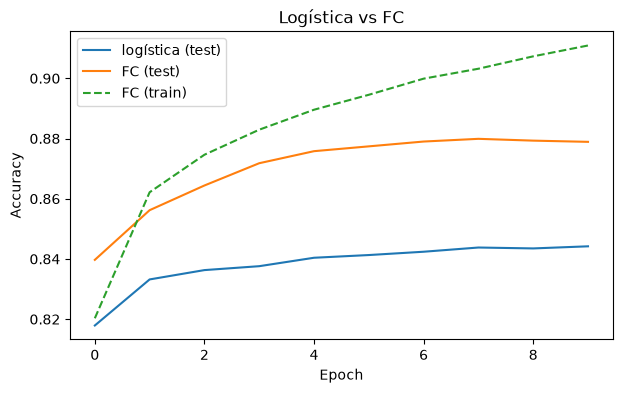

In [14]:
compile_model(fc_model)
hist_fc = fc_model.fit(X_train, y_train, validation_data=(X_test, y_test),
                       epochs=epochs, batch_size=batch_size, shuffle=True, verbose=0)
fc_loss, fc_acc = fc_model.evaluate(X_test, y_test, batch_size=batch_size, verbose=0)

print(f"{'Modelo':22s}{'Parámetros':>12s}{'Train acc':>11s}{'Test acc':>10s}")
print(f"{'Regresión logística':22s}{logistic_model.count_params():>12,}{hist_logistic.history['accuracy'][-1]:>11.4f}{res_logistic[1]:>10.4f}")
print(f"{'FC (784-128-10)':22s}{fc_model.count_params():>12,}{hist_fc.history['accuracy'][-1]:>11.4f}{fc_acc:>10.4f}")

plt.figure(figsize=(7, 4))
plt.plot(hist_logistic.history["val_accuracy"], label="logística (test)")
plt.plot(hist_fc.history["val_accuracy"], label="FC (test)")
plt.plot(hist_fc.history["accuracy"], "--", label="FC (train)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Logística vs FC")
plt.show()

### 7.2 ¿Qué clases se confunden más? (red FC)

Exactitud por clase (FC):
  Trouser       97.1%
  Bag           96.3%
  Sneaker       96.1%
  Sandal        95.7%
  Ankle boot    94.8%
  Dress         87.3%
  Pullover      87.2%
  T-shirt/top   85.3%
  Coat          76.0%
  Shirt         63.1%

Confusiones más frecuentes (real -> predicha):
  Coat         -> Pullover     179 veces
  Shirt        -> T-shirt/top  138 veces
  Shirt        -> Pullover     133 veces
  T-shirt/top  -> Shirt        97 veces
  Shirt        -> Coat         66 veces
  Pullover     -> Coat         55 veces


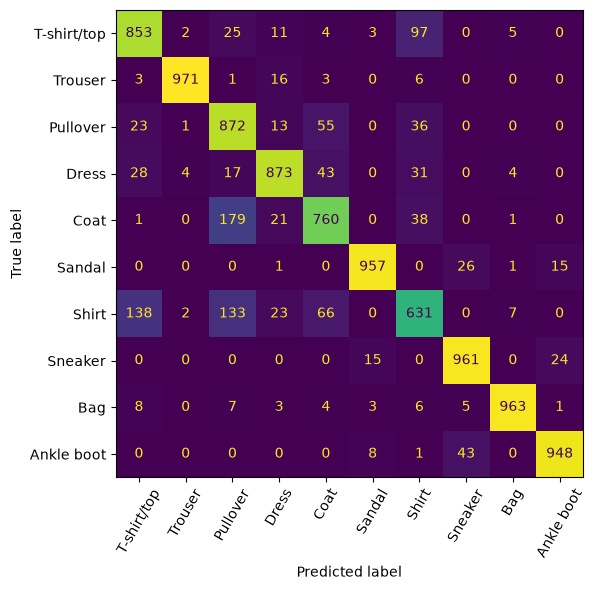

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pred_fc = np.argmax(fc_model.predict(X_test, batch_size=256, verbose=0), axis=1)
cm = confusion_matrix(y_test, pred_fc)
acc_clase = cm.diagonal() / cm.sum(axis=1)

print("Exactitud por clase (FC):")
for i in np.argsort(-acc_clase):
    print(f"  {class_names[i]:12s} {acc_clase[i]*100:5.1f}%")

off = cm.copy(); np.fill_diagonal(off, 0)
print("\nConfusiones más frecuentes (real -> predicha):")
for idx in np.argsort(-off, axis=None)[:6]:
    a, b = divmod(idx, 10)
    print(f"  {class_names[a]:12s} -> {class_names[b]:12s} {off[a, b]} veces")

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=60, colorbar=False)
plt.tight_layout(); plt.show()

### 7.3 Variantes de la red: segunda capa oculta, `tanh`/`sigmoid`, `Dropout`, `batch_size` y `lr_rate`

Se cambia **una sola cosa por vez** respecto a la red FC base (784-128-10, ReLU, batch 64, lr 0.001) para que la comparación sea limpia. Cada variante se entrena desde cero con la misma semilla.

In [16]:
import time, re

def correr(nombre, capas, bs=64, lr=0.001, ep=10):
    keras.utils.set_random_seed(SEED)
    m = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten()] + capas + [layers.Dense(10)], name=re.sub(r"[^A-Za-z0-9_]", "_", nombre))
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss=loss_fn, metrics=["accuracy"])
    t0 = time.time()
    h = m.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=ep, batch_size=bs, shuffle=True, verbose=0)
    tr, te = h.history["accuracy"][-1], h.history["val_accuracy"][-1]
    print(f"{nombre:34s} params={m.count_params():>8,}  train={tr:.4f}  test={te:.4f}  brecha={tr-te:+.4f}  ({time.time()-t0:.0f}s)")
    return nombre, tr, te

resultados = []
resultados.append(correr("base ReLU 128",                [layers.Dense(128, activation="relu")]))
resultados.append(correr("2 capas ocultas 128-128",      [layers.Dense(128, activation="relu"), layers.Dense(128, activation="relu")]))
resultados.append(correr("activación tanh",              [layers.Dense(128, activation="tanh")]))
resultados.append(correr("activación sigmoid",           [layers.Dense(128, activation="sigmoid")]))
resultados.append(correr("Dropout(0.3) tras la oculta",  [layers.Dense(128, activation="relu"), layers.Dropout(0.3)]))
resultados.append(correr("batch_size=16",                [layers.Dense(128, activation="relu")], bs=16))
resultados.append(correr("batch_size=256",               [layers.Dense(128, activation="relu")], bs=256))
resultados.append(correr("lr=0.01",                      [layers.Dense(128, activation="relu")], lr=0.01))
resultados.append(correr("lr=0.0001",                    [layers.Dense(128, activation="relu")], lr=0.0001))
resultados.append(correr("30 épocas",                    [layers.Dense(128, activation="relu")], ep=30))

base ReLU 128                      params= 101,770  train=0.9099  test=0.8805  brecha=+0.0294  (23s)


2 capas ocultas 128-128            params= 118,282  train=0.9133  test=0.8766  brecha=+0.0367  (27s)


activación tanh                    params= 101,770  train=0.9130  test=0.8794  brecha=+0.0336  (32s)


activación sigmoid                 params= 101,770  train=0.9020  test=0.8747  brecha=+0.0273  (43s)


Dropout(0.3) tras la oculta        params= 101,770  train=0.8872  test=0.8769  brecha=+0.0103  (75s)


batch_size=16                      params= 101,770  train=0.9140  test=0.8798  brecha=+0.0342  (204s)


batch_size=256                     params= 101,770  train=0.8989  test=0.8650  brecha=+0.0339  (22s)


lr=0.01                            params= 101,770  train=0.8788  test=0.8487  brecha=+0.0301  (110s)


lr=0.0001                          params= 101,770  train=0.8754  test=0.8597  brecha=+0.0157  (57s)


30 épocas                          params= 101,770  train=0.9515  test=0.8755  brecha=+0.0760  (107s)


### 7.4 Resumen de los experimentos

| Experimento | Train | Test | Brecha | Lectura |
|---|---:|---:|---:|---|
| Regresión logística (7,850 parámetros) | 0.8625 | 0.8442 | +0.0183 | Línea base lineal |
| FC base 784-128-10, ReLU | 0.9099 | 0.8805 | +0.0294 | +3.6 puntos sobre la logística |
| 2 capas ocultas 128-128 | 0.9133 | 0.8766 | +0.0367 | No mejora en prueba; más brecha |
| `tanh` | 0.9130 | 0.8794 | +0.0336 | Equivalente a ReLU |
| `sigmoid` | 0.9020 | 0.8747 | +0.0273 | Algo peor, menor accuracy de entrenamiento |
| `Dropout(0.3)` | 0.8872 | 0.8769 | +0.0103 | Reduce la brecha a un tercio, pero el test no sube |
| `batch_size=16` | 0.9140 | 0.8798 | +0.0342 | Igual en prueba, 9 veces más lento (204 s) |
| `batch_size=256` | 0.8989 | 0.8650 | +0.0339 | Peor: menos actualizaciones en 10 épocas |
| `lr=0.01` | 0.8788 | 0.8487 | +0.0301 | Peor: pasos demasiado grandes |
| `lr=0.0001` | 0.8754 | 0.8597 | +0.0157 | Peor: sin converger en 10 épocas |
| 30 épocas | 0.9515 | 0.8755 | +0.0760 | Train sube, test no: overfitting claro |

**Lo que dicen los datos:**

1. La capa oculta con ReLU sí sirve: 88.05% contra 84.42% de la logística en prueba (en la corrida de 7.1, 87.89% contra 84.42%; la diferencia entre 88.05 y 87.89 es variación entre dos entrenamientos de la misma arquitectura: el de 7.1 parte de los pesos ya creados en la sección 2 y el de 7.3 reinicia la semilla). Coincide con el rango esperado del notebook (83 a 85% y 87 a 89%).
2. Ningún cambio de arquitectura o activación subió el test más de ~0.2 puntos sobre la base. Con 10 épocas, entre 87.5% y 88.1% es esencialmente el techo de una red totalmente conectada en este problema; diferencias de décimas están dentro del ruido y no deben leerse como mejoras (no se repitió cada variante con varias semillas).
3. Entrenar 30 épocas es la evidencia más clara de sobreajuste: el accuracy de entrenamiento pasa de 0.9099 a 0.9515 y el de prueba baja de 0.8805 a 0.8755; la brecha se multiplica por 2.6.
4. Los errores se concentran en la ropa de torso: `Shirt` es la clase más difícil (63.1% de exactitud), seguida de `Coat` (76.0%). Las confusiones más repetidas son Coat con Pullover (179), Shirt con T-shirt/top (138) y Shirt con Pullover (133). `Trouser` (97.1%), `Bag` y `Sneaker` casi no fallan. Es la dificultad que anticipa el notebook, y es la que una CNN debería atacar.
5. Hiperparámetros: `lr=0.01` y `lr=0.0001` son peores que 0.001 en las mismas 10 épocas; `batch_size=256` hace menos actualizaciones y queda atrás; `batch_size=16` no gana nada y cuesta 9 veces más tiempo.

---
## 6. Conclusiones y próximos pasos

### Resultados esperados

Los valores exactos dependen de la inicialización y del entrenamiento, pero normalmente veremos una diferencia clara entre ambos modelos:

| Modelo | Accuracy en prueba (aprox.) | Parámetros |
|---|---:|---:|
| Regresión Logística | ~83–85% | 7,850 |
| **FC Neural Network** (784→128→10) | **~87–89%** | 101,770 |

La red neuronal FC tiene mayor capacidad que la regresión logística porque la combinación:

```text
Dense(128) → ReLU
```

introduce una transformación no lineal del espacio de entrada.

Fashion-MNIST permite ver mejor esta diferencia que MNIST porque varias clases son visualmente similares y no pueden separarse tan fácilmente mediante una transformación lineal.

### Conceptos que vimos

```text
Datos
  ↓
mini-batches
  ↓
Forward pass
  ↓
Logits
  ↓
Cross-Entropy Loss
  ↓
Backpropagation
  ↓
Adam
  ↓
Actualización de parámetros
```

Keras 3 encapsula este ciclo con:

```python
model.compile(...)
model.fit(...)
model.evaluate(...)
```

pero los conceptos matemáticos subyacentes siguen siendo los mismos.

### Experimentos sugeridos

- Cambia `MODEL_TYPE = "fc"` y compara con la regresión logística.
- Identifica cuáles clases se confunden más.
- Añade una segunda capa oculta.
- Cambia `relu` por `tanh` o `sigmoid`.
- Cambia `batch_size`.
- Prueba distintos valores de `lr_rate`.
- Aumenta o reduce el número de epochs.
- Añade `Dropout`.
- Compara train accuracy y test accuracy.
- Como siguiente paso, compara esta red fully-connected con una **CNN**, que aprovecha explícitamente la estructura espacial de las imágenes.

---

### Equivalencias principales: PyTorch → Keras 3

| PyTorch | Keras 3 |
|---|---|
| `torchvision.datasets.FashionMNIST` | `keras.datasets.fashion_mnist.load_data()` |
| `DataLoader` | `model.fit(..., batch_size=...)` |
| `torch.nn.Linear` | `layers.Dense` |
| `torch.nn.functional.relu` | `activation="relu"` |
| `CrossEntropyLoss` | `SparseCategoricalCrossentropy(from_logits=True)` |
| `torch.optim.Adam` | `keras.optimizers.Adam` |
| `loss.backward()` | autodiferenciación interna durante `fit()` |
| `optimizer.step()` | actualización interna durante `fit()` |
| `torch.argmax` | `keras.ops.argmax` |
| `torch.nn.functional.softmax` | `keras.ops.softmax` |
| `model.eval()` + `no_grad()` | `model.evaluate()` o `model(..., training=False)` |
